In [83]:
import numpy as np
import pandas as pd
from google.cloud import storage
from google.oauth2 import service_account
from datetime import datetime
from sdv.single_table import CTGANSynthesizer,TVAESynthesizer
from sdv.metadata import SingleTableMetadata
from sklearn import preprocessing,metrics
from sklearn.preprocessing import OneHotEncoder
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import random
import pandas_gbq
import json
import statistics




In [84]:
with open("finops-55-0c8185e843cd.json","r") as f:
    json_data=json.load(f)
f.close()
from google.cloud import bigquery
cred = service_account.Credentials.from_service_account_info(json_data)
client = bigquery.Client(project=json_data['project_id'],credentials=cred)

# Perform a query.
QUERY = (
    '''SELECT distinct a.*,b.Family FROM
    `finops-55.billing_1.gcp_cost_usage_focus_view` a
    left join
    `finops-55.billing_1.service_family_mapping` b
    on lower(a.ServiceName)=lower(b.Service_Name) and date(a.chargeperiodstart)<'2025-08-12'
    ''' )
query_job = client.query(QUERY)  # API request
df_gcp_focus=query_job.to_dataframe()  # Waits for query to finish
df_gcp_focus.columns=[i.lower() for i in df_gcp_focus]
df_gcp_focus['cloud']='GCP'


/opt/anaconda3/envs/venv/lib/python3.10/site-packages/google/cloud/bigquery/table.py:1965: UserWarning:

BigQuery Storage module not found, fetch data with the REST endpoint instead.



In [85]:
df_gcp_focus.drop('servicecategory',axis=1,inplace=True)
df_gcp_focus.rename(columns={'family':'servicecategory'},inplace=True)

In [86]:
# Perform a query.
QUERY = (
    '''SELECT distinct * FROM 
    `finops-55.billing_1.aws_focus_usage_and_cost` where date(chargeperiodstart)<'2025-08-12'
    ''' )
query_job = client.query(QUERY)  # API request
df_aws_focus=query_job.to_dataframe()  # Waits for query to finish
df_aws_focus['cloud']='AWS'

df_aws_focus.columns=[i.lower() for i in df_aws_focus]

/opt/anaconda3/envs/venv/lib/python3.10/site-packages/google/cloud/bigquery/table.py:1965: UserWarning:

BigQuery Storage module not found, fetch data with the REST endpoint instead.



In [87]:
# Perform a query.
QUERY = (
    '''SELECT distinct * FROM  `finops-55.billing_1.azure_focus_usage_and_cost` 
    where date(chargeperiodstart)<'2025-08-12'
    ''' )
query_job = client.query(QUERY)  # API request
df_azure_focus=query_job.to_dataframe()  # Waits for query to finish
df_azure_focus['cloud']='AZURE'
df_azure_focus.columns=[i.lower() for i in df_azure_focus]

/opt/anaconda3/envs/venv/lib/python3.10/site-packages/google/cloud/bigquery/table.py:1965: UserWarning:

BigQuery Storage module not found, fetch data with the REST endpoint instead.



In [88]:
df_azure_focus.shape,df_aws_focus.shape,df_gcp_focus.shape

((563, 97), (9215, 49), (45801, 45))

In [89]:
df_azure_focus3 = df_azure_focus.copy()
df_aws_focus3 = df_aws_focus.copy()
df_gcp_focus3 = df_gcp_focus.copy()

In [90]:

# df_aws_focus3['chargeperiodstart'] = pd.to_datetime(df_aws_focus3['chargeperiodstart'])
# df_aws_focus3['chargeperiodend'] = pd.to_datetime(df_aws_focus3['chargeperiodend'])
# df_aws_focus3['diff'] = df_aws_focus3['chargeperiodend'] - df_aws_focus3['chargeperiodstart']
# set(df_aws_focus3['diff'])

In [91]:
def convert_datetime(df):
    df['chargeperiodstart'] = pd.to_datetime(df['chargeperiodstart'])
    df['chargeperiodend'] = pd.to_datetime(df['chargeperiodend'])
    df['billingperiodend'] = pd.to_datetime(df['billingperiodend'])
    df['billingperiodstart'] = pd.to_datetime(df['billingperiodstart'])
    df['chargeperiodstart_year'] = df['chargeperiodstart'].dt.year
    df['chargeperiodstart_month'] = df['chargeperiodstart'].dt.month
    df['chargeperiodstart_day'] = df['chargeperiodstart'].dt.day
    df = df.drop(['chargeperiodstart','chargeperiodend','billingperiodend','billingperiodstart'],axis=1)
    for i in ['chargeperiodstart_month','chargeperiodstart_day','chargeperiodstart_year']:
        df[i]=df[i].astype('str')  
    for i in ['billedcost', 'contractedcost', 'contractedunitprice', 'effectivecost', 'listcost',
    'listunitprice', 'pricingquantity','consumedquantity']:
        df[i]=df[i].astype(np.number)
    return df

In [92]:
df_aws_focus3 = convert_datetime(df_aws_focus3)
df_gcp_focus3 = convert_datetime(df_gcp_focus3)
df_azure_focus3 = convert_datetime(df_azure_focus3)

/opt/anaconda3/envs/venv/lib/python3.10/site-packages/pandas/core/dtypes/common.py:1663: DeprecationWarning:

Converting `np.inexact` or `np.floating` to a dtype is deprecated. The current result is `float64` which is not strictly correct.

/opt/anaconda3/envs/venv/lib/python3.10/site-packages/pandas/core/dtypes/common.py:1663: DeprecationWarning:

Converting `np.inexact` or `np.floating` to a dtype is deprecated. The current result is `float64` which is not strictly correct.

/opt/anaconda3/envs/venv/lib/python3.10/site-packages/pandas/core/dtypes/common.py:1663: DeprecationWarning:

Converting `np.inexact` or `np.floating` to a dtype is deprecated. The current result is `float64` which is not strictly correct.

/opt/anaconda3/envs/venv/lib/python3.10/site-packages/pandas/core/dtypes/common.py:1663: DeprecationWarning:

Converting `np.inexact` or `np.floating` to a dtype is deprecated. The current result is `float64` which is not strictly correct.

/opt/anaconda3/envs/venv/lib/python3

In [93]:
df_aws_focus3.shape

(9215, 48)

In [94]:
df_gcp_focus3.shape

(45801, 44)

In [95]:
df_azure_focus3.shape

(563, 96)

In [96]:
a=df_gcp_focus3.columns
a=[i.lower() for i in a]
b=df_aws_focus3.columns
b=[i.lower() for i in b]
c=df_azure_focus3.columns
c=[i.lower() for i in c]


In [97]:
col_gcp=pd.DataFrame({'GCP_Columns':a})
col_aws=pd.DataFrame({'AWS_Columns':b})
col_azure=pd.DataFrame({'AZURE_Columns':c})


In [98]:
col_total=col_gcp.merge(col_aws,how="inner",left_on="GCP_Columns",right_on="AWS_Columns").merge(col_azure,how="inner",left_on="GCP_Columns",right_on="AZURE_Columns")

In [99]:
col_total

,GCP_Columns,AWS_Columns,AZURE_Columns
0,billedcost,billedcost,billedcost
1,billingaccountid,billingaccountid,billingaccountid
2,billingcurrency,billingcurrency,billingcurrency
3,chargecategory,chargecategory,chargecategory
4,chargeclass,chargeclass,chargeclass
5,chargedescription,chargedescription,chargedescription
6,commitmentdiscountcategory,commitmentdiscountcategory,commitmentdiscountcategory
7,commitmentdiscountid,commitmentdiscountid,commitmentdiscountid
8,commitmentdiscountname,commitmentdiscountname,commitmentdiscountname
9,consumedquantity,consumedquantity,consumedquantity


In [100]:
df_gcp_focus_1 = df_gcp_focus3[col_total['GCP_Columns'].tolist()]
#Removing id columns
id_columns=[]
for i in df_gcp_focus_1.columns:
    if 'id' in i[-2:]:
        id_columns.append(i)
id_columns
df_gcp_focus_1.drop(id_columns,axis=1,inplace=True)
#Removing Redundant columns
df_gcp_focus_1.drop(['providername','publishername'],axis=1,inplace=True)



In [101]:
print(df_gcp_focus_1.isnull().sum()/len(df_gcp_focus_1)*100)

billedcost                      0.000000
billingcurrency                 0.000000
chargecategory                  0.000000
chargeclass                   100.000000
chargedescription               0.000000
commitmentdiscountcategory    100.000000
commitmentdiscountname        100.000000
consumedquantity                0.004367
consumedunit                    0.004367
contractedcost                  0.000000
contractedunitprice             0.004367
effectivecost                   0.000000
listcost                        0.004367
listunitprice                 100.000000
pricingcategory                 0.004367
pricingquantity                 0.004367
pricingunit                     0.004367
regionname                     24.971071
resourcename                   50.429030
resourcetype                   36.486103
servicename                     0.000000
tags                            0.000000
servicecategory                39.579922
cloud                           0.000000
chargeperiodstar

In [102]:
df_aws_focus_1 = df_aws_focus3[col_total['AWS_Columns'].tolist()]
#Removing id columns
id_columns=[]
for i in df_aws_focus_1.columns:
    if 'id' in i[-2:]:
        id_columns.append(i)
id_columns
df_aws_focus_1.drop(id_columns,axis=1,inplace=True)
df_aws_focus_1.isnull().sum()/len(df_aws_focus_1)*100
#Removing Redundant columns
df_aws_focus_1.drop(['providername','publishername'],axis=1,inplace=True)

df_aws_focus_1.isnull().sum()/len(df_aws_focus_1)*100

billedcost                      0.000000
billingcurrency                 0.000000
chargecategory                  0.000000
chargeclass                   100.000000
chargedescription               0.000000
commitmentdiscountcategory    100.000000
commitmentdiscountname        100.000000
consumedquantity                1.258817
consumedunit                    1.258817
contractedcost                  0.000000
contractedunitprice             1.258817
effectivecost                   0.000000
listcost                        0.000000
listunitprice                   1.258817
pricingcategory                 1.258817
pricingquantity                 1.258817
pricingunit                     1.258817
regionname                      1.258817
resourcename                  100.000000
resourcetype                   74.997287
servicename                     0.000000
tags                            0.000000
servicecategory                 0.000000
cloud                           0.000000
chargeperiodstar

In [103]:
df_azure_focus_1 = df_azure_focus3[col_total['AZURE_Columns'].tolist()]
#Removing id columns
id_columns=[]
for i in df_azure_focus_1.columns:
    if 'id' in i[-2:]:
        id_columns.append(i)
id_columns
df_azure_focus_1.drop(id_columns,axis=1,inplace=True)
#Removing Redundant columns
df_azure_focus_1.drop(['providername','publishername'],axis=1,inplace=True)

df_azure_focus_1.isnull().sum()/len(df_azure_focus_1)*100

billedcost                      0.000000
billingcurrency                 0.000000
chargecategory                  0.000000
chargeclass                   100.000000
chargedescription               0.000000
commitmentdiscountcategory    100.000000
commitmentdiscountname        100.000000
consumedquantity                0.000000
consumedunit                    0.000000
contractedcost                  0.000000
contractedunitprice             0.000000
effectivecost                   0.000000
listcost                        0.000000
listunitprice                   0.000000
pricingcategory                 0.000000
pricingquantity                 0.000000
pricingunit                     0.000000
regionname                      0.000000
resourcename                    0.000000
resourcetype                    0.000000
servicename                     0.000000
tags                           90.230906
servicecategory                 0.000000
cloud                           0.000000
chargeperiodstar

In [104]:
df_gcp_focus_1.drop('tags',axis=1,inplace=True)
df_aws_focus_1.drop('tags',axis=1,inplace=True)
df_azure_focus_1.drop('tags',axis=1,inplace=True)

In [105]:
df_gcp_focus_1.servicename.unique()

array(['Invoice', 'Cloud Run', 'Compute Engine', 'Cloud Storage',
       'Cloud Logging', 'BigQuery', 'VM Manager', 'BigQuery Storage API',
       'Deep Learning VM', 'Dataplex', 'Artifact Registry',
       'Secret Manager', 'Notebooks', 'Networking', 'Cloud Build',
       'Cloud Scheduler', 'Cloud Monitoring', 'Vertex AI',
       'Cloud Document AI API', 'Gemini API'], dtype=object)

In [106]:
df_full = pd.concat([df_gcp_focus_1,df_aws_focus_1,df_azure_focus_1])

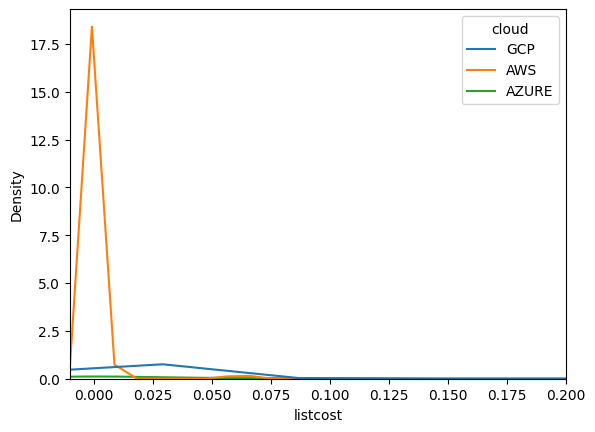

In [148]:
sns.kdeplot(df_full.reset_index(drop=True),x='listcost',hue='cloud')
plt.xlim(-0.01,0.2)
# plt.grid()
plt.show()

In [152]:
import plotly.express as px
fig = px.scatter(df_full, x="listcost", y="consumedquantity", color="cloud",opacity=0.8)
fig.update_xaxes(range=[0,1])
fig.show()

In [107]:
null_cols=[]
for i in df_full.columns:
    if df_full[i].isnull().sum()/len(df_full)*100>40:
        null_cols.append(i)
null_cols.append('contractedunitprice')

In [108]:
df_aws_focus_1.drop(null_cols,axis=1,inplace=True)
df_gcp_focus_1.drop(null_cols,axis=1,inplace=True)
df_azure_focus_1.drop(null_cols,axis=1,inplace=True)

In [109]:
df_sample = pd.concat([df_azure_focus_1,df_gcp_focus_1,df_aws_focus_1])
# df_sample = df_sample.drop(['effectivecost','contractedcost'],axis=1)

In [110]:
from statsmodels.stats.outliers_influence import variance_inflation_factor


X = df_sample.select_dtypes(include=np.number).dropna()

vif_data = pd.DataFrame()
vif_data["feature"] = X.columns

vif_data["VIF"] = [variance_inflation_factor(X.values, i)
                          for i in range(len(X.columns))]

In [111]:
vif_data

,feature,VIF
0,billedcost,0.998313
1,consumedquantity,1.000522
2,contractedcost,0.999738
3,effectivecost,0.998313
4,listcost,0.999738
5,pricingquantity,0.998162


In [112]:
def preprocessing_all(df):
    for i in df.select_dtypes(include='object').columns:
        df[i] = df[i].str.lower()
        if df[i].isnull().sum()/len(df)>0 and i not in ['regionname','servicecategory']:
            print(i,df[i].isnull().sum())
            df[i].fillna(df.groupby(['cloud','servicename'])[i].transform(statistics.mode),inplace=True)
        elif df[i].isnull().sum()/len(df)>0 and i=='regionname':
            df[i].fillna(statistics.mode(df[i]),inplace=True)
        elif df[i].isnull().sum()/len(df)>0 and i=='servicecategory':
            df[i].fillna('Other',inplace=True)
    for i in df.select_dtypes(include=np.number).columns:
        if df[i].isnull().sum()/len(df)>0:
            df[i].fillna(df.groupby(['cloud','servicename'])[i].transform('mean'),inplace=True)
    consumedquantity=[]
    consumedunit = []

    for i in range(len(df)):
        if df['consumedunit'].iloc[i]=='bytes':
            consumedquantity.append(df['consumedquantity'].iloc[i]*10**(-9))
            consumedunit.append('gb')
        elif df['consumedunit'].iloc[i]=='seconds':
            consumedquantity.append(df['consumedquantity'].iloc[i]/3600)
            consumedunit.append('hours')
        elif df['consumedunit'].iloc[i]=='byte-seconds':
            consumedquantity.append(df['consumedquantity'].iloc[i]*10**(-9)/3600)
            consumedunit.append('gb-months')
        else:
            consumedquantity.append(df['consumedquantity'].iloc[i])
            consumedunit.append(df['consumedunit'].iloc[i])
    df['consumedquantity']= consumedquantity
    df['consumedunit'] = consumedunit
    df = df[df['consumedunit']!='requests'].reset_index(drop=True)
    df = df.drop(['effectivecost','contractedcost'],axis=1)
    return df

In [113]:
df_gcp_focus_1 = preprocessing_all(df_gcp_focus_1)
df_aws_focus_1 = preprocessing_all(df_aws_focus_1)
df_azure_focus_1 = preprocessing_all(df_azure_focus_1)

consumedunit 2
pricingcategory 2
pricingunit 2


/var/folders/xl/c80qvx9n3mg7_rtyjf_s4v_00000gn/T/ipykernel_14910/179318625.py:6: FutureWarning:

A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.



/var/folders/xl/c80qvx9n3mg7_rtyjf_s4v_00000gn/T/ipykernel_14910/179318625.py:6: FutureWarning:

A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df

consumedunit 116
pricingcategory 116
pricingunit 116


/var/folders/xl/c80qvx9n3mg7_rtyjf_s4v_00000gn/T/ipykernel_14910/179318625.py:6: FutureWarning:

A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.



/var/folders/xl/c80qvx9n3mg7_rtyjf_s4v_00000gn/T/ipykernel_14910/179318625.py:6: FutureWarning:

A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df

In [114]:
df_sample = pd.concat([df_azure_focus_1,df_gcp_focus_1,df_aws_focus_1])
# df_sample = df_sample.drop(['effectivecost','contractedcost'],axis=1)
from statsmodels.stats.outliers_influence import variance_inflation_factor


X = df_sample.select_dtypes(include=np.number).dropna()

vif_data = pd.DataFrame()
vif_data["feature"] = X.columns

vif_data["VIF"] = [variance_inflation_factor(X.values, i)
                          for i in range(len(X.columns))]
vif_data

,feature,VIF
0,billedcost,1.037747
1,consumedquantity,1.003227
2,listcost,1.036629
3,pricingquantity,1.004542


In [115]:
df_sample.select_dtypes(include=np.number).skew()

billedcost           91.782309
consumedquantity     93.310412
listcost            127.979785
pricingquantity      98.437519
dtype: float64

In [116]:
# 'byte-seconds', 'requests', 'seconds', nan, 'bytes', 'gb',
#        'gb/month', 'hours', 'units', 'units/month', 'api calls',
#        'bucket-mo', 'gb-months', 'invocations', 'vcpu-hours', 'events'],

In [117]:
# Non-Aggregation
df_gcp_focus_2= df_gcp_focus_1.copy()
df_aws_focus_2 = df_aws_focus_1.copy()
df_azure_focus_2 = df_azure_focus_1.copy()

#Aggregation
# list1=df_gcp_focus_1.columns.tolist()
# list2=['billedcost','effectivecost',  'consumedquantity', 'pricingquantity','listcost','contractedcost']
# for i in list2:
#     list1.remove(i)
# print(list1)
# df_gcp_focus_2 = df_gcp_focus_1.groupby(list1,dropna=False)[list2].sum().reset_index()
# df_aws_focus_2 = df_aws_focus_1.groupby(list1,dropna=False)[list2].sum().reset_index()
# df_azure_focus_2 = df_azure_focus_1.groupby(list1,dropna=False)[list2].sum().reset_index()


In [118]:

# df_gcp_focus_2 = df_gcp_focus_1.copy()
# df_aws_focus_2 = df_aws_focus_1.copy()
# df_azure_focus_2 = df_azure_focus_1.copy()

In [119]:
df_gcp_focus_2.shape,df_aws_focus_2.shape,df_azure_focus_2.shape



((43956, 17), (8311, 17), (563, 17))

In [120]:
from datetime import datetime
date = datetime.now()
year_limit = date.year
month_limit = date.month
year_limit,month_limit


(2025, 9)

In [121]:
def synthesis_data(df,cloud):
    month_range = np.arange(1,13,1)
    date = datetime.now()
    year_limit = date.year
    month_limit = date.month
    synthetic_data_final = pd.DataFrame()
    i = 2025
    for j in month_range:
        if j<=6:
            metadata = SingleTableMetadata()
            metadata.detect_from_dataframe(df)
            epochs_list=[100,150,300]
            batch_size_list = [100,250,500]
            epoch = random.choice(epochs_list)
            batch_size = random.choice(batch_size_list)
            if cloud == 'GCP':
                epoch = 100
                batch_size = 700
            print(epoch,batch_size)
            synthesizer = CTGANSynthesizer(metadata,epochs=epoch,batch_size=batch_size,cuda=True)
            synthesizer.fit(df)
            if cloud=='AWS':
                synthetic_data = synthesizer.sample(num_rows=int(len(df)))
            elif cloud=='AZURE':
                synthetic_data = synthesizer.sample(num_rows=int(len(df)*10))
            else:
                synthetic_data = synthesizer.sample(num_rows=int(len(df)*0.5))
            synthetic_data['chargeperiodstart_year']=i
            synthetic_data['chargeperiodstart_month']=j
            synthetic_data[['chargeperiodstart_year','chargeperiodstart_month']]=synthetic_data[['chargeperiodstart_year',
                                                                                                 'chargeperiodstart_month']].astype('object')
            synthetic_data_final = pd.concat([synthetic_data_final,synthetic_data])
            print("Size_batch:",synthetic_data_final.shape)
        else:
            continue
    return synthetic_data_final

In [122]:
syn_aws = synthesis_data(df_aws_focus_2,'AWS')
syn_azure = synthesis_data(df_azure_focus_2,'AZURE')

100 100


/opt/anaconda3/envs/venv/lib/python3.10/site-packages/sdv/single_table/base.py:163: FutureWarning:

The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.

/opt/anaconda3/envs/venv/lib/python3.10/site-packages/sdv/single_table/base.py:129: UserWarning:

We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.



Size_batch: (8311, 17)
300 250


/opt/anaconda3/envs/venv/lib/python3.10/site-packages/sdv/single_table/base.py:163: FutureWarning:

The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.

/opt/anaconda3/envs/venv/lib/python3.10/site-packages/sdv/single_table/base.py:129: UserWarning:

We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.



Size_batch: (16622, 17)
300 250


...

Size_batch: (22520, 17)
300 250


/opt/anaconda3/envs/venv/lib/python3.10/site-packages/sdv/single_table/base.py:163: FutureWarning:

The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.

/opt/anaconda3/envs/venv/lib/python3.10/site-packages/sdv/single_table/base.py:129: UserWarning:

We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.



Size_batch: (28150, 17)
300 100


/opt/anaconda3/envs/venv/lib/python3.10/site-packages/sdv/single_table/base.py:163: FutureWarning:

The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.

/opt/anaconda3/envs/venv/lib/python3.10/site-packages/sdv/single_table/base.py:129: UserWarning:

We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.



Size_batch: (33780, 17)


In [123]:
syn_gcp = synthesis_data(df_gcp_focus_2,'GCP')


100 700


/opt/anaconda3/envs/venv/lib/python3.10/site-packages/sdv/single_table/base.py:163: FutureWarning:

The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.

/opt/anaconda3/envs/venv/lib/python3.10/site-packages/sdv/single_table/base.py:129: UserWarning:

We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.



Size_batch: (21978, 17)
100 700


/opt/anaconda3/envs/venv/lib/python3.10/site-packages/sdv/single_table/base.py:163: FutureWarning:

The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.

/opt/anaconda3/envs/venv/lib/python3.10/site-packages/sdv/single_table/base.py:129: UserWarning:

We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.



Size_batch: (43956, 17)
100 700


...

Size_batch: (87912, 17)
100 700


/opt/anaconda3/envs/venv/lib/python3.10/site-packages/sdv/single_table/base.py:163: FutureWarning:

The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.

/opt/anaconda3/envs/venv/lib/python3.10/site-packages/sdv/single_table/base.py:129: UserWarning:

We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.



Size_batch: (109890, 17)
100 700


/opt/anaconda3/envs/venv/lib/python3.10/site-packages/sdv/single_table/base.py:163: FutureWarning:

The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.

/opt/anaconda3/envs/venv/lib/python3.10/site-packages/sdv/single_table/base.py:129: UserWarning:

We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.



Size_batch: (131868, 17)


In [124]:
# from sdv.evaluation.single_table import get_column_plot

# metadata = SingleTableMetadata()
# metadata.detect_from_dataframe(df_gcp_focus_2)
# fig = get_column_plot(
#     real_data=df_gcp_focus_2,
#     synthetic_data=syn_gcp,
#     column_name='listcost',
#     metadata=metadata
# )
    
# fig.show()

In [125]:
syn_aws.shape,syn_azure.shape,syn_gcp.shape

((49866, 17), (33780, 17), (131868, 17))

In [126]:
df_model = pd.concat([df_gcp_focus_2,df_azure_focus_2,df_aws_focus_2,syn_aws,syn_azure,syn_gcp]).reset_index(drop=True)


In [127]:
df_model.isnull().sum()

billedcost                    0
billingcurrency               0
chargecategory                0
chargedescription             0
consumedquantity            422
consumedunit               7611
listcost                      2
pricingcategory            7646
pricingquantity            3829
pricingunit                7521
regionname                    0
servicename                   0
servicecategory               0
cloud                         0
chargeperiodstart_year        0
chargeperiodstart_month       0
chargeperiodstart_day         0
dtype: int64

In [128]:
#Aggregation
list1=df_model.columns.tolist()
list2=['billedcost', 'consumedquantity', 'pricingquantity','listcost']
for i in list2:
    list1.remove(i)
print(list1)
df_model_agg = df_model.groupby(list1,dropna=False)[list2].sum().reset_index()
# df_aws_focus_2 = df_aws_focus_1.groupby(list1,dropna=False)[list2].sum().reset_index()
# df_azure_focus_2 = df_azure_focus_1.groupby(list1,dropna=False)[list2].sum().reset_index()

['billingcurrency', 'chargecategory', 'chargedescription', 'consumedunit', 'pricingcategory', 'pricingunit', 'regionname', 'servicename', 'servicecategory', 'cloud', 'chargeperiodstart_year', 'chargeperiodstart_month', 'chargeperiodstart_day']


In [129]:
df_model.shape,df_model_agg.shape

((268344, 17), (108327, 17))

In [130]:
# pandas_gbq.to_gbq(syn_gcp,'finops-55.billing_1.synthesized_gcp_data_train',project_id='finops-55',if_exists="replace",credentials=cred)
# pandas_gbq.to_gbq(syn_aws,'finops-55.billing_1.synthesized_aws_data_train',project_id='finops-55',if_exists="replace",credentials=cred)
# pandas_gbq.to_gbq(syn_azure,'finops-55.billing_1.synthesized_azure_data_train',project_id='finops-55',if_exists="replace",credentials=cred)

In [131]:
df_model_num = df_model.select_dtypes(include=np.number)

In [132]:
df_model.dtypes

billedcost                 float64
billingcurrency             object
chargecategory              object
chargedescription           object
consumedquantity           float64
consumedunit                object
listcost                   float64
pricingcategory             object
pricingquantity            float64
pricingunit                 object
regionname                  object
servicename                 object
servicecategory             object
cloud                       object
chargeperiodstart_year      object
chargeperiodstart_month     object
chargeperiodstart_day       object
dtype: object

In [133]:
df_model.columns

Index(['billedcost', 'billingcurrency', 'chargecategory', 'chargedescription',
       'consumedquantity', 'consumedunit', 'listcost', 'pricingcategory',
       'pricingquantity', 'pricingunit', 'regionname', 'servicename',
       'servicecategory', 'cloud', 'chargeperiodstart_year',
       'chargeperiodstart_month', 'chargeperiodstart_day'],
      dtype='object')

In [134]:
df_model['chargeperiodstart_day'].unique()

array(['1', '21', '16', '26', '17', '28', '25', '15', '27', '29', '18',
       '19', '31', '20', '24', '23', '30', '22', '9', '7', '13', '10',
       '6', '8', '11', '12', '14', '5', '4', '2', '3'], dtype=object)

In [135]:
df_model

,billedcost,billingcurrency,chargecategory,chargedescription,consumedquantity,consumedunit,listcost,pricingcategory,pricingquantity,pricingunit,regionname,servicename,servicecategory,cloud,chargeperiodstart_year,chargeperiodstart_month,chargeperiodstart_day
0,0.000000,gbp,adjustment,rounding error,NaN,NaN,NaN,NaN,NaN,NaN,iowa,invoice,Other,gcp,2025,7,1
1,0.000000,gbp,adjustment,rounding error,NaN,NaN,NaN,NaN,NaN,NaN,iowa,invoice,Other,gcp,2025,7,1
2,0.000000,gbp,usage,services memory (request-based billing),0.003743,gb-months,0.000022,standard,1.0,gibibyte second,belgium,cloud run,serverless,gcp,2025,7,21
3,0.000000,gbp,usage,services memory (request-based billing),0.000954,gb-months,0.000005,standard,1.0,gibibyte second,belgium,cloud run,serverless,gcp,2025,7,16
4,0.000001,gbp,usage,services memory (request-based billing),0.000000,gb-months,0.000000,standard,1.0,gibibyte second,belgium,cloud run,serverless,gcp,2025,7,16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
268339,-0.000006,gbp,usage,build time e2-standard-2,-0.015713,gb-months,-0.000001,standard,1.0,minute,london,cloud build,cloud application ecosystem,gcp,2025,6,20
268340,-0.000006,gbp,usage,artifact registry storage,0.527874,gb-months,0.000120,standard,1.0,gibibyte month,london,artifact registry,other,gcp,2025,6,21
268341,-0.000006,gbp,usage,metric volume,0.333314,gb,0.000116,standard,1.0,mebibyte,iowa,cloud monitoring,Other,gcp,2025,6,9
268342,0.000006,gbp,usage,metadata storage,-0.015713,gb-months,-0.000001,standard,1.0,gibibyte month,belgium,vertex ai,cloud ai,gcp,2025,6,7


In [136]:
df_model_agg.groupby(['cloud','servicename','consumedunit'])[['consumedquantity',  'listcost',
       ]].mean().sort_values(by=['cloud','listcost'],ascending=[True,False])

consumedquantity  listcost
cloud servicename                  consumedunit                            
aws   amazon elastic compute cloud hours                 1.844337  0.016763
      amazon virtual private cloud hours                 3.577798  0.011544
                                   vcpu-hours            2.095857  0.009102
      aws data transfer            events                0.959660  0.004459
      amazon sagemaker             hours                 1.362874  0.003276
...                                                           ...       ...
gcp   cloud storage                gb-months             2.775136  0.000392
      cloud logging                gb-months             0.338868  0.000345
      cloud storage                gb                    0.180976  0.000339
      artifact registry            gb                    0.265109  0.000317
      dataplex                     gb                    0.681670  0.000291

[181 rows x 2 columns]

In [137]:
df_model_agg['consumedunit'].unique()

array([nan, 'gb-months', 'hours', 'gb', 'gb/month', 'units',
       'units/month', 'api calls', 'bucket-mo', 'events', 'invocations',
       'vcpu-hours'], dtype=object)

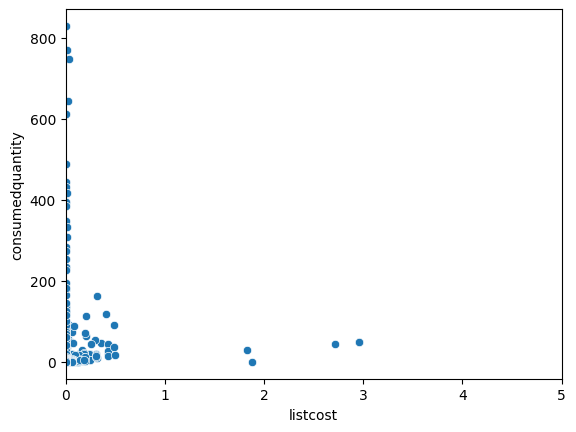

In [138]:
sns.scatterplot(df_model_agg[(df_model_agg['cloud']=='aws')],x='listcost',y='consumedquantity')
plt.xlim(0,5)
plt.show()

In [139]:
# pandas_gbq.to_gbq(df_model,'finops-55.billing_1.synthesized_data_train',project_id='finops-55',if_exists="replace",credentials=cred)


In [140]:
# df_model_num = df_model.select_dtypes(include=np.number).reset_index(drop=True)
# for i in df_model_num.columns:
#     for j in df_model_num.columns:
#         if i!=j:
#             sns.scatterplot(df_model_num,x=i,y=j)
#             plt.title(f"{i} vs {j}")
#             plt.show()

In [141]:
df_model.groupby(['cloud','servicename'])[['billedcost',
        'consumedquantity', 'pricingquantity', 'listcost']].sum().sort_values(by=['cloud','listcost'],ascending=[True,False])

billedcost  consumedquantity  \
cloud servicename                                                   
aws   amazon elastic compute cloud    43.028985      5.512523e+03   
      amazon virtual private cloud     9.668553      3.328366e+03   
      amazon sagemaker                 4.873366      9.865190e+02   
      aws data transfer                3.980226      2.466225e+03   
      amazon elastic file system       1.320884      2.271748e+02   
      amazon simple storage service    1.161899      5.534115e+02   
      cloudwatch events                1.269056      1.259248e+03   
      aws cloudtrail                   2.044807      1.680378e+04   
      aws lambda                       0.828876      6.961666e+02   
      amazoncloudwatch                 0.658187      6.131472e+02   
      aws service catalog              0.158656      4.427727e+02   
      aws cloudshell                   0.222505      1.850303e+02   
azure storage accounts               278.230590      7.534528e+06   
      virtual machines               163.032316      2.571464e+06   
      virtual network                 63.077579      1.282258e+06   
      azure app service               37.289948      5.879090e+05   
      key vault                        9.750637      9.054782e+04   
      azure ai services                9.030406      1.301175e+05   
      azure monitor                    6.008787      1.612459e+05   
      network watcher                  3.956200      4.916041e+04   
gcp   notebooks                       -0.001793      1.028654e+06   
      compute engine                  -0.016422      1.802676e+05   
      cloud run                       -0.001494      1.141071e+04   
      bigquery                        -0.002324      2.093266e+04   
      deep learning vm                -0.001680      3.824127e+04   
      invoice                         -0.001789      2.780717e+04   
      dataplex                        -0.005094      4.980510e+04   
      artifact registry               -0.006516      4.913786e+04   
      vertex ai                       -0.003856      5.639572e+04   
      cloud logging                   -0.004736      1.568596e+03   
      secret manager                  -0.000425      7.445125e+03   
      cloud monitoring                -0.004818      2.554538e+03   
      cloud build                     -0.001340      1.484195e+03   
      cloud storage                   -0.002003      5.789219e+03   
      bigquery storage api            -0.000025      1.045793e+03   

                                     pricingquantity    listcost  
cloud servicename                                                 
aws   amazon elastic compute cloud       5873.366456   48.238319  
      amazon virtual private cloud       3303.293068   10.275797  
      amazon sagemaker                   1017.601875    5.290962  
      aws data transfer                  2647.050755    2.593800  
      amazon elastic file system          313.933903    1.462828  
      amazon simple storage service       688.528402    1.311767  
      cloudwatch events                  1386.367394    1.085171  
      aws cloudtrail                    16486.385538    0.909068  
      aws lambda                         1124.074248    0.470612  
      amazoncloudwatch                    841.207629    0.405237  
      aws service catalog                 574.037265    0.136984  
      aws cloudshell                      291.780836    0.083191  
azure storage accounts                  36094.400216  479.601851  
      virtual machines                  21932.308829  323.772338  
      virtual network                   11178.589651  132.597659  
      azure app service                  5494.902415   58.068202  
      key vault                          1434.159719   22.776362  
      azure ai services                  1510.758924   18.127997  
      azure monitor                       899.903632    8.313415  
      network watcher                     516.873202    8.025286  
gcp   not

In [69]:
df_model_agg_change=df_model_agg[df_model_agg['servicename'].isin([i.lower() for i in ['Amazon Simple Storage Service','Amazon Virtual Private Cloud'
                                                                   ,'Amazon Elastic Compute Cloud','AWS Data Transfer','Compute Engine',
                                                                   'Cloud Storage','BigQuery']])]
df_model_agg_nochange=df_model_agg[~df_model_agg['servicename'].isin([i.lower() for i in ['Amazon Simple Storage Service','Amazon Virtual Private Cloud'
                                                                   ,'Amazon Elastic Compute Cloud','AWS Data Transfer','Compute Engine',
                                                                   'Cloud Storage','BigQuery']])]

In [70]:
batch_size = np.arange(1000,len(df_model_agg_change)+1000,1000)
batch_size


array([ 1000,  2000,  3000,  4000,  5000,  6000,  7000,  8000,  9000,
       10000, 11000, 12000, 13000, 14000, 15000, 16000, 17000, 18000,
       19000, 20000, 21000, 22000, 23000, 24000, 25000, 26000, 27000,
       28000, 29000, 30000, 31000, 32000, 33000, 34000, 35000, 36000,
       37000, 38000, 39000, 40000, 41000, 42000, 43000])

In [71]:
df_model_agg_change.shape,df_model_agg_nochange.shape

((42227, 17), (67012, 17))

In [82]:
# df_model_agg.groupby(['cloud','servicename'])[['billedcost',
#         'consumedquantity', 'pricingquantity', 'listcost']].sum().sort_values(by=['cloud','listcost'],ascending=[True,False])
# df_model_agg_change_emp = pd.DataFrame()
# for k in batch_size:
#     try:
#         df_one_temp = df_model_agg_change[k-1000:k]
#     except:
#         df_one_temp = df_model_agg_change[k-1000:]
#     for i in ['amazon simple storage service','amazon virtual private cloud','amazon elastic compute cloud','aws data transfer','compute engine','cloud storage','bigquery']:
#         if ('AWS' in i) or ('Amazon' in i):
#             factor = 1+random.uniform(1,3)
#         else:
#             factor = 1+random.uniform(0.2,0.75)
#         # print(i,factor)
#         for j in ['billedcost', 'consumedquantity', 'pricingquantity', 'listcost']:
#             try:
#                 df_one_temp.loc[df_one_temp['servicename']==i,j] = factor* df_one_temp.loc[df_one_temp['servicename']==i,j]+random.uniform(0,1)
#             except:
#                 df_one_temp=factor*df_one_temp[df_one_temp['servicename']==i][j]

#     df_model_agg_change_emp=pd.concat([df_model_agg_change_emp,df_one_temp])

In [73]:
df_model_agg_change_emp.shape

(42227, 17)

In [66]:
df_model_agg=pd.concat([df_model_agg_change,df_model_agg_nochange])


In [67]:
df_model_agg.groupby(['cloud','servicename'])[['billedcost',
        'consumedquantity', 'pricingquantity', 'listcost']].sum().sort_values(by=['cloud','listcost'],ascending=[True,False])

billedcost  consumedquantity  \
cloud servicename                                                     
aws   amazon elastic compute cloud    5126.181178      1.354168e+04   
      amazon simple storage service   1601.079635      2.467066e+03   
      amazon virtual private cloud     592.869524      5.459897e+03   
      aws data transfer                254.378817      4.372691e+03   
      amazon sagemaker                   4.026151      3.819215e+02   
      amazon elastic file system         1.145941      2.374906e+02   
      aws cloudtrail                     1.405251      1.846371e+04   
      cloudwatch events                  1.209684      1.311202e+03   
      amazoncloudwatch                   0.543807      6.982577e+02   
      aws lambda                         0.464027      5.772602e+02   
      aws cloudshell                     0.456198      1.802275e+02   
      aws service catalog                0.207836      3.217518e+02   
azure storage accounts                 291.397177      6.885911e+06   
      virtual machines                 177.386675      3.228051e+06   
      virtual network                   91.839816      1.590088e+06   
      azure app service                 45.566878      7.934833e+05   
      key vault                         10.413936      2.614907e+05   
      azure ai services                  9.116832      1.096964e+05   
      network watcher                    2.988575      1.686224e+04   
      azure monitor                      5.414640      5.590544e+04   
gcp   compute engine                 10587.127619      2.724304e+05   
      bigquery                        2027.966676      3.803812e+04   
      cloud storage                   1509.198129      9.761406e+03   
      notebooks                          0.017775      1.064842e+06   
      cloud run                          0.013721      1.364556e+04   
      deep learning vm                   0.010708      4.586821e+04   
      invoice                            0.006446      2.856302e+04   
      dataplex                           0.019545      4.996828e+04   
      artifact registry                  0.018249      5.109394e+04   
      secret manager                     0.007696      9.156437e+03   
      vertex ai                          0.009213      4.144498e+04   
      cloud build                        0.002270      2.131221e+03   
      cloud logging                      0.029016      2.234436e+03   
      cloud monitoring                   0.018726      1.617038e+03   
      bigquery storage api               0.000319      2.335806e+03   

                                     pricingquantity      listcost  
cloud servicename                                                   
aws   amazon elastic compute cloud      14870.193290   3391.909347  
      amazon simple storage service      2795.020511   2531.233533  
      amazon virtual private cloud       5341.253079    664.927341  
      aws data transfer                  4594.353737    304.803328  
      amazon sagemaker                    457.377631      4.323270  
      amazon elastic file system          243.115383      1.368023  
      aws cloudtrail                    18826.824913      0.833874  
      cloudwatch events                  1692.833856      0.740995  
      amazoncloudwatch                    916.022155      0.395579  
      aws lambda                          945.572888      0.171064  
      aws cloudshell                      331.374473      0.148339  
      aws service catalog                 510.771733      0.139234  
azure storage accounts                  82109.120625    272.622963  
      virtual machines                  39427.548446    167.930101  
      virtual network                   23316.272139     85.404712  
      azure app service                  8765.345470     34.436847  
      key vault                          2136.044016      8.360689  
      azure ai services                  1937.375184      6.550893  
      network watcher          

In [75]:
df_model_agg.shape

(109239, 17)

In [76]:
q1=np.quantile(df_model_agg['listcost'],0.25)
q3=np.quantile(df_model_agg['listcost'],0.75)
iqr=q3-q1
a = q1-1.5*iqr
b = q3+1.5*iqr

In [77]:
len(df_model_agg[(df_model_agg['listcost']<a) | (df_model_agg['listcost']>b)])/len(df_model_agg)

0.001949853074451432

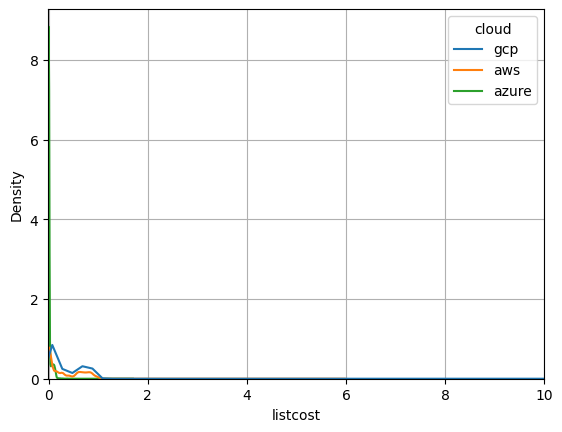

In [78]:
sns.kdeplot(df_model_agg,x='listcost',hue='cloud')
plt.xlim(-0.01,10)
plt.grid()
plt.show()

In [142]:
import plotly.express as px
fig = px.scatter(df_model_agg, x="listcost", y="consumedquantity", color="cloud",)
fig.update_xaxes(range=[0,3])


fig.show()

In [80]:
df_model_agg.groupby(['consumedunit'])['consumedquantity'].mean()

consumedunit
api calls        1.409010
bucket-mo        0.660897
events          15.968774
gb             105.906581
gb-months       41.688155
gb/month       342.632164
hours          157.661340
invocations      1.457546
units          432.404272
units/month    371.118312
vcpu-hours       1.784127
Name: consumedquantity, dtype: float64

In [81]:
pandas_gbq.to_gbq(df_model_agg,'finops-55.billing_1.synthesized_data_train_genl',project_id='finops-55',if_exists="replace",credentials=cred)

/opt/anaconda3/envs/venv/lib/python3.10/site-packages/pandas_gbq/schema/pandas_to_bigquery.py:157: UserWarning:

Could not determine the type of columns: chargeperiodstart_year, chargeperiodstart_month

100%|██████████| 1/1 [00:00<00:00, 7194.35it/s]
